
# Next Word Prediction Using LSTM

## Innomatics Research Labs — Deep Learning NLP Project

**Student Name:** Mahesh Rebba

**Enrollment Number:** 81010202726

**Project:** Next Word Prediction

**Domain:** Natural Language Processing / Deep Learning

### Problem Statement

Next Word Prediction is an NLP task in which a model
predicts the most probable next word based on a given
sequence of text.

### Project Objective

Build a deep learning model using LSTM to learn
linguistic patterns from a text corpus and predict
the next word in a sequence.

### Technologies

- Python
- NumPy
- Pandas
- NLTK
- TensorFlow / Keras
- Matplotlib
- Streamlit (optional demonstration)

### Project Workflow

1. Data Collection
2. Text Cleaning and Preprocessing
3. Tokenization and Sequence Generation
4. LSTM Model Building
5. Model Training
6. Evaluation
7. Next Word Prediction
8. Model Demonstration



## Step 2: Data Collection

### Dataset: Alice's Adventures in Wonderland

**Author:** Lewis Carroll

**Source:** NLTK Gutenberg Corpus / Project Gutenberg

**Language:** English

### Reason for Dataset Selection

The dataset contains continuous narrative English text
with complete sentences and contextual word sequences.

It is suitable for training a next-word prediction
model using an LSTM neural network.

The corpus is publicly available and is used for
educational natural language processing research.

### Objective

Load the dataset and inspect its size, text content,
and vocabulary characteristics.


In [1]:

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import tensorflow as tf

from nltk.corpus import gutenberg
from collections import Counter

# Download Gutenberg corpus
nltk.download("gutenberg")

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")


[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Unzipping corpora/gutenberg.zip.


TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:

# Display available Gutenberg files
print("Available Gutenberg Files:")
print(gutenberg.fileids())

# Load Alice's Adventures in Wonderland
corpus = gutenberg.raw("carroll-alice.txt")

print("\nCorpus Loaded Successfully!")

print("Total Characters:", len(corpus))
print("Total Words (approx):", len(corpus.split()))

print("\nFirst 1000 Characters:")
print(corpus[:1000])


Available Gutenberg Files:
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Corpus Loaded Successfully!
Total Characters: 144395
Total Words (approx): 26443

First 1000 Characters:
[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversations in
it, 'and what is the use of a book,' thought Alice 'without pictures or
conversation?'

So she was considering in her own mind (as well as sh

In [3]:

# Basic corpus statistics
words = re.findall(r"[a-z]+", corpus.lower())

word_counts = Counter(words)

print("Total Word Tokens:", len(words))
print("Unique Words:", len(word_counts))

print("\nTop 15 Most Frequent Words:")
for word, count in word_counts.most_common(15):
    print(f"{word}: {count}")

print("\nCorpus Character Count:", len(corpus))


Total Word Tokens: 27335
Unique Words: 2569

Top 15 Most Frequent Words:
the: 1642
and: 872
to: 729
a: 632
it: 595
she: 553
i: 545
of: 514
said: 462
you: 411
alice: 398
in: 369
was: 357
that: 315
as: 263

Corpus Character Count: 144395



### Step 2 — Data Collection Observations

The dataset was successfully loaded from the
NLTK Gutenberg corpus.

Dataset: Alice's Adventures in Wonderland
Author: Lewis Carroll

**Initial Statistics:**
- Total characters: 144,395
- Approximate whitespace-separated words: 26,443
- Alphabetic word tokens: 27,335
- Unique alphabetic words: 2,569

The most frequent words include:
the, and, to, a, it, she, i, of, said, and you.

The dataset contains continuous narrative text,
which is suitable for sequence-based language modeling.

**Conclusion:**

The dataset provides a useful foundation for
developing a next-word prediction model using LSTM.

The next stage will clean and prepare the text for
tokenization and sequence generation.



## Step 3 — Text Cleaning and Preprocessing

### Objective

Clean the raw text corpus before tokenization
and next-word sequence generation.

### Preprocessing Steps

1. Remove the book's introductory metadata.
2. Remove chapter headings.
3. Convert text to lowercase.
4. Identify individual sentences.
5. Remove unwanted punctuation and special characters.
6. Normalize extra whitespace.
7. Remove empty or unusably short sentences.

### Important Decision

Stopwords will be preserved because they carry
important grammatical information for next-word
prediction.

### Expected Outcome

A collection of cleaned English sentences suitable
for generating input and target word sequences.


In [4]:
from nltk.tokenize import sent_tokenize

# Required sentence tokenizer resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("Text preprocessing libraries loaded successfully!")


Text preprocessing libraries loaded successfully!


In [5]:

# Create a working copy
clean_corpus = corpus

# Remove the introductory book metadata
clean_corpus = re.sub(
    r"^\s*\[Alice's Adventures in Wonderland.*?\]",
    " ",
    clean_corpus,
    count=1,
    flags=re.DOTALL
)

# Remove chapter headings
clean_corpus = re.sub(
    r"(?im)^\s*CHAPTER\s+[IVXLCDM]+\.[^\n]*",
    " ",
    clean_corpus
)

# Normalize whitespace
clean_corpus = re.sub(
    r"\s+",
    " ",
    clean_corpus
).strip()

print("Original Characters:", len(corpus))
print("Cleaned Characters:", len(clean_corpus))

print("\nFirst 500 Characters:")
print(clean_corpus[:500])


Original Characters: 144395
Cleaned Characters: 142007

First 500 Characters:
Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, 'and what is the use of a book,' thought Alice 'without pictures or conversation?' So she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain would be worth the trouble of gettin


In [6]:

# Split text into sentences
sentences = sent_tokenize(clean_corpus)

print("Total Sentences:", len(sentences))

print("\nFirst 5 Sentences:")

for i, sentence in enumerate(sentences[:5], start=1):
    print(f"\nSentence {i}:")
    print(sentence)


Total Sentences: 1614

First 5 Sentences:

Sentence 1:
Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, 'and what is the use of a book,' thought Alice 'without pictures or conversation?'

Sentence 2:
So she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain would be worth the trouble of getting up and picking the daisies, when suddenly a White Rabbit with pink eyes ran close by her.

Sentence 3:
There was nothing so VERY remarkable in that; nor did Alice think it so VERY much out of the way to hear the Rabbit say to itself, 'Oh dear!

Sentence 4:
Oh dear!

Sentence 5:
I shall be late!'


In [7]:

def clean_sentence(sentence):

    # Convert to lowercase
    sentence = sentence.lower()

    # Replace punctuation and numbers with spaces
    sentence = re.sub(r"[^a-z\s]", " ", sentence)

    # Remove extra spaces
    sentence = re.sub(r"\s+", " ", sentence).strip()

    return sentence


# Clean the sentences
cleaned_sentences = [
    clean_sentence(sentence)
    for sentence in sentences
]

# Keep sentences with at least 3 words
cleaned_sentences = [
    sentence
    for sentence in cleaned_sentences
    if len(sentence.split()) >= 3
]

print("Total Cleaned Sentences:", len(cleaned_sentences))

print("\nFirst 5 Cleaned Sentences:")
for i, sentence in enumerate(cleaned_sentences[:5], start=1):
    print(f"{i}. {sentence}")


Total Cleaned Sentences: 1496

First 5 Cleaned Sentences:
1. alice was beginning to get very tired of sitting by her sister on the bank and of having nothing to do once or twice she had peeped into the book her sister was reading but it had no pictures or conversations in it and what is the use of a book thought alice without pictures or conversation
2. so she was considering in her own mind as well as she could for the hot day made her feel very sleepy and stupid whether the pleasure of making a daisy chain would be worth the trouble of getting up and picking the daisies when suddenly a white rabbit with pink eyes ran close by her
3. there was nothing so very remarkable in that nor did alice think it so very much out of the way to hear the rabbit say to itself oh dear
4. i shall be late
5. when she thought it over afterwards it occurred to her that she ought to have wondered at this but at the time it all seemed quite natural but when the rabbit actually took a watch out of its waistc

In [8]:

# Convert to a DataFrame for analysis
df_text = pd.DataFrame({
    "sentence": cleaned_sentences
})

# Calculate word counts
df_text["word_count"] = df_text["sentence"].apply(
    lambda text: len(text.split())
)

print("Dataset Shape:", df_text.shape)

print("\nMissing Values:")
print(df_text.isnull().sum())

print("\nSentence Length Statistics:")
display(df_text["word_count"].describe())

print("\nFirst 5 Records:")
display(df_text.head())

print("\nTotal Cleaned Word Tokens:")
print(df_text["word_count"].sum())

print("\nUnique Cleaned Words:")
print(
    len(
        set(
            " ".join(cleaned_sentences).split()
        )
    )
)


Dataset Shape: (1496, 2)

Missing Values:
sentence      0
word_count    0
dtype: int64

Sentence Length Statistics:


,word_count
count,1496.000000
mean,18.082888
std,16.861341
min,3.000000
25%,7.000000
50%,13.000000
75%,23.000000
max,180.000000



First 5 Records:


,sentence,word_count
0,alice was beginning to get very tired of sitti...,57
1,so she was considering in her own mind as well...,56
2,there was nothing so very remarkable in that n...,29
3,i shall be late,4
4,when she thought it over afterwards it occurre...,109



Total Cleaned Word Tokens:
27052

Unique Cleaned Words:
2549



### Step 3 — Text Preprocessing Findings

The text corpus from Alice's Adventures in Wonderland
was successfully cleaned and prepared for NLP modeling.

**Dataset Statistics:**

- Total cleaned sentences: 1,496
- Total word tokens: 27,052
- Unique words: 2,549
- Average sentence length: 18.08 words
- Median sentence length: 13 words
- Maximum sentence length: 180 words
- Missing values: 0

**Observations:**

1. Most sentences contain fewer than 24 words.
2. Some long sentences contain up to 180 words.
3. Stopwords were preserved to maintain grammatical context.
4. Punctuation, special characters, and numbers were removed.
5. The dataset is ready for tokenization and sequence generation.

**Conclusion:**

The cleaned dataset provides a suitable foundation
for training an LSTM-based next-word prediction model.



## Step 4 — Tokenization and Sequence Generation

### Objective

Convert cleaned text sentences into numerical tokens
and create supervised training examples for
next-word prediction.

### Approach

1. Split sentences into training and validation sets.
2. Fit a tokenizer on training sentences only.
3. Convert text into sequences of integer token IDs.
4. Generate input sequences and next-word targets.
5. Verify the vocabulary size and generated samples.

### Important

The dataset is split before tokenization to reduce
data leakage between training and validation sets.

Stopwords are retained because they help the model
learn grammatical sentence structure.


In [9]:

from sklearn.model_selection import train_test_split

train_sentences, val_sentences = train_test_split(
    cleaned_sentences,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training Sentences:", len(train_sentences))
print("Validation Sentences:", len(val_sentences))

print("\nSample Training Sentence:")
print(train_sentences[0])

print("\nSample Validation Sentence:")
print(val_sentences[0])


Training Sentences: 1196
Validation Sentences: 300

Sample Training Sentence:
at any rate i ll never go there again

Sample Validation Sentence:
said the rabbit in a low hurried tone


In [10]:

from tensorflow.keras.preprocessing.text import Tokenizer

# Maximum vocabulary size
MAX_VOCAB = 3000

# Create tokenizer
tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    oov_token="<OOV>",
    filters=""
)

# Learn vocabulary from training sentences only
tokenizer.fit_on_texts(train_sentences)

# Determine usable vocabulary size
vocab_size = min(
    MAX_VOCAB,
    len(tokenizer.word_index) + 1
)

print("Unique Training Vocabulary:",
      len(tokenizer.word_index))

print("Model Vocabulary Size:", vocab_size)

print("\nFirst 15 Words in Vocabulary:")
print(list(tokenizer.word_index.items())[:15])


Unique Training Vocabulary: 2298
Model Vocabulary Size: 2299

First 15 Words in Vocabulary:
[('<OOV>', 1), ('the', 2), ('and', 3), ('to', 4), ('a', 5), ('it', 6), ('she', 7), ('i', 8), ('of', 9), ('said', 10), ('you', 11), ('was', 12), ('alice', 13), ('in', 14), ('that', 15)]


In [11]:

CONTEXT_LENGTH = 20

def generate_sequences(sentences, tokenizer, context_length=20):
    inputs = []
    targets = []

    for sentence in sentences:

        # Convert sentence into token IDs
        tokens = tokenizer.texts_to_sequences(
            [sentence]
        )[0]

        # Generate next-word examples
        for i in range(1, len(tokens)):

            start = max(0, i - context_length)

            input_sequence = tokens[start:i]
            target_word = tokens[i]

            inputs.append(input_sequence)
            targets.append(target_word)

    return inputs, targets


train_inputs, train_targets = generate_sequences(
    train_sentences,
    tokenizer,
    CONTEXT_LENGTH
)

val_inputs, val_targets = generate_sequences(
    val_sentences,
    tokenizer,
    CONTEXT_LENGTH
)

print("Training Examples:", len(train_inputs))
print("Validation Examples:", len(val_inputs))

print("\nFirst Input Token Sequence:")
print(train_inputs[0])

print("\nFirst Target Token:")
print(train_targets[0])


Training Examples: 20313
Validation Examples: 5243

First Input Token Sequence:
[19]

First Target Token:
134


In [12]:

# Create reverse word lookup
index_to_word = {
    index: word
    for word, index in tokenizer.word_index.items()
    if index < vocab_size
}

print("First 5 Training Examples:\n")

for i in range(min(5, len(train_inputs))):

    input_words = [
        index_to_word.get(token, "<OOV>")
        for token in train_inputs[i]
    ]

    target_word = index_to_word.get(
        train_targets[i],
        "<OOV>"
    )

    print("Input:", " ".join(input_words))
    print("Target:", target_word)
    print("-" * 50)


First 5 Training Examples:

Input: at
Target: any
--------------------------------------------------
Input: at any
Target: rate
--------------------------------------------------
Input: at any rate
Target: i
--------------------------------------------------
Input: at any rate i
Target: ll
--------------------------------------------------
Input: at any rate i ll
Target: never
--------------------------------------------------


In [13]:

print("Vocabulary Size:", vocab_size)

print("Training Examples:", len(train_inputs))
print("Validation Examples:", len(val_inputs))

print("\nMaximum Input Length:",
      max(map(len, train_inputs)))

print("Minimum Input Length:",
      min(map(len, train_inputs)))

print("\nMaximum Target ID:",
      max(train_targets))

print("Minimum Target ID:",
      min(train_targets))

assert len(train_inputs) == len(train_targets)
assert len(val_inputs) == len(val_targets)

assert max(train_targets) < vocab_size
assert max(val_targets) < vocab_size

print("\nSequence Generation Verified!")


Vocabulary Size: 2299
Training Examples: 20313
Validation Examples: 5243

Maximum Input Length: 20
Minimum Input Length: 1

Maximum Target ID: 2298
Minimum Target ID: 2

Sequence Generation Verified!



## Step 5 — Sequence Padding

### Objective

Convert variable-length input sequences into fixed-length
numerical arrays suitable for LSTM model training.

### Approach

1. Use a maximum context length of 20 tokens.
2. Apply pre-padding to shorter sequences.
3. Preserve the most recent words for long sequences.
4. Convert target words into integer arrays.
5. Verify shapes and token ID ranges.

### Reason

LSTM models process batches of fixed-shaped input
sequences. Padding ensures that all training
examples have a consistent shape.

Integer target labels will be used with
Sparse Categorical Crossentropy loss.


In [14]:

from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

print("Padding libraries imported successfully!")


Padding libraries imported successfully!


In [15]:

# Context length defined in Step 4
CONTEXT_LENGTH = 20

# Pad training inputs
X_train_pad = pad_sequences(
    train_inputs,
    maxlen=CONTEXT_LENGTH,
    padding="pre",
    truncating="pre"
)

# Pad validation inputs
X_val_pad = pad_sequences(
    val_inputs,
    maxlen=CONTEXT_LENGTH,
    padding="pre",
    truncating="pre"
)

# Convert next-word targets into NumPy arrays
y_train_next = np.array(
    train_targets,
    dtype=np.int32
)

y_val_next = np.array(
    val_targets,
    dtype=np.int32
)

print("Training Input Shape:", X_train_pad.shape)
print("Validation Input Shape:", X_val_pad.shape)

print("Training Target Shape:", y_train_next.shape)
print("Validation Target Shape:", y_val_next.shape)


Training Input Shape: (20313, 20)
Validation Input Shape: (5243, 20)
Training Target Shape: (20313,)
Validation Target Shape: (5243,)


In [16]:

print("Original First Input:")
print(train_inputs[0])

print("\nPadded First Input:")
print(X_train_pad[0])

print("\nFirst Target ID:")
print(y_train_next[0])

print("\nFirst Target Word:")
print(index_to_word.get(y_train_next[0], "<OOV>"))

print("\nExample With More Context:")
print(X_train_pad[4])

print("\nCorresponding Target:")
print(index_to_word.get(y_train_next[4], "<OOV>"))


Original First Input:
[19]

Padded First Input:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 19]

First Target ID:
134

First Target Word:
any

Example With More Context:
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  19 134 383
   8  93]

Corresponding Target:
never


In [17]:

assert X_train_pad.shape == (20313, 20)
assert X_val_pad.shape == (5243, 20)

assert len(X_train_pad) == len(y_train_next)
assert len(X_val_pad) == len(y_val_next)

assert X_train_pad.min() >= 0
assert X_train_pad.max() < vocab_size

assert y_train_next.min() >= 1
assert y_train_next.max() < vocab_size

print("Sequence Padding Verified Successfully!")


Sequence Padding Verified Successfully!



### Step 5 — Sequence Padding Observations

The generated next-word input sequences were converted
into fixed-length numerical arrays.

**Configuration:**
- Context length: 20 tokens
- Padding method: Pre-padding
- Truncation method: Pre-truncation

**Prepared Data:**
- Training examples: 20,313
- Validation examples: 5,243
- Training input shape: (20313, 20)
- Validation input shape: (5243, 20)

The target words were converted into integer labels.

**Conclusion:**

The dataset is ready for training an Embedding + LSTM
model using Sparse Categorical Crossentropy loss.



## Step 6 — LSTM Model Architecture

### Objective

Develop a deep learning model that predicts the next
word based on a sequence of up to 20 previous words.

### Architecture

1. Input Layer — Accepts 20 integer tokens.
2. Embedding Layer — Learns 64-dimensional word vectors.
3. LSTM Layer — Uses 128 recurrent units.
4. Dropout Layer — Applies 30% dropout.
5. Dense Layer — Predicts vocabulary probabilities
   using Softmax activation.

### Model Configuration

- Vocabulary size: 2,299
- Context length: 20
- Embedding dimension: 64
- LSTM units: 128
- Dropout rate: 0.30
- Optimizer: Adam
- Loss: Sparse Categorical Crossentropy

### Reason for Choosing LSTM

LSTM networks are designed to learn sequential
dependencies and preserve relevant context from
previous words.

Softmax is used because next-word prediction is
a multiclass classification problem.


In [20]:

import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dropout,
    Dense
)

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow Version:", tf.__version__)
print("Model libraries imported successfully!")


TensorFlow Version: 2.21.0
Model libraries imported successfully!


In [21]:

# Model configuration
EMBEDDING_DIM = 64
LSTM_UNITS = 128
DROPOUT_RATE = 0.30

# Clear previous models
tf.keras.backend.clear_session()

# Build model
next_word_model = Sequential([
    Input(shape=(CONTEXT_LENGTH,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    LSTM(LSTM_UNITS),

    Dropout(DROPOUT_RATE),

    Dense(
        vocab_size,
        activation="softmax"
    )
], name="Next_Word_Prediction_LSTM")

# Display architecture
next_word_model.summary()


Model: "Next_Word_Prediction_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 20, 64)         │       147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2299)           │       296,571 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 542,523 (2.07 MB)

 Trainable params: 542,523 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:

next_word_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print("LSTM model compiled successfully!")


LSTM model compiled successfully!


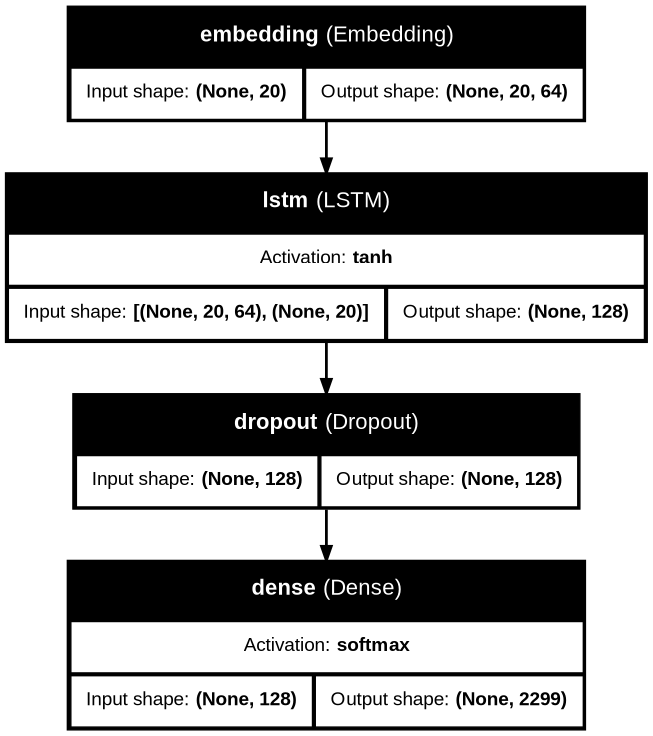

In [25]:

from tensorflow.keras.utils import plot_model

plot_model(
    next_word_model,
    to_file="next_word_lstm_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    dpi=100
)


In [24]:
!pip -q install pydot


### Step 6 — Model Architecture Observations

An LSTM-based next-word prediction model was built
using TensorFlow and Keras.

**Architecture:**

- Embedding: 64-dimensional word representations
- LSTM: 128 recurrent units
- Dropout: 30%
- Dense: Softmax output over 2,299 token IDs

The model accepts fixed-length sequences of 20 tokens
and predicts the probability of the next word.

**Loss Function:**
Sparse Categorical Crossentropy

**Optimizer:**
Adam with learning rate 0.001

**Conclusion:**

The LSTM architecture is ready for model training
and evaluation.



## Step 7 — LSTM Model Training

### Objective

Train the LSTM model to predict the next word
from a sequence of up to 20 preceding words.

### Training Configuration

- Optimizer: Adam
- Learning Rate: 0.001
- Loss Function: Sparse Categorical Crossentropy
- Evaluation Metric: Accuracy
- Maximum Epochs: 20
- Batch Size: 64
- EarlyStopping Patience: 4

### Training Strategy

1. Train using 20,313 input-target examples.
2. Validate using 5,243 examples.
3. Monitor training and validation accuracy.
4. Monitor training and validation loss.
5. Apply EarlyStopping to reduce overfitting.
6. Save the best model based on validation loss.

### Expected Outcome

A trained LSTM model capable of generating
next-word predictions from input text.


In [26]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# Save the best-performing model
model_checkpoint = ModelCheckpoint(
    filepath="best_next_word_lstm.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Reduce learning rate if validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Training callbacks configured successfully!")


Training callbacks configured successfully!


In [27]:

history = next_word_model.fit(
    X_train_pad,
    y_train_next,

    validation_data=(
        X_val_pad,
        y_val_next
    ),

    epochs=20,
    batch_size=64,

    callbacks=callbacks,
    verbose=1
)

print("\nLSTM Training Completed!")


Epoch 1/20
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.0531 - loss: 6.7382
Epoch 1: val_loss improved from None to 6.09468, saving model to best_next_word_lstm.keras

Epoch 1: finished saving model to best_next_word_lstm.keras
318/318 ━━━━━━━━━━━━━━━━━━━━ 30s 84ms/step - accuracy: 0.0567 - loss: 6.3566 - val_accuracy: 0.0641 - val_loss: 6.0947 - learning_rate: 0.0010
Epoch 2/20
317/318 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.0594 - loss: 5.9060
Epoch 2: val_loss improved from 6.09468 to 6.05607, saving model to best_next_word_lstm.keras

Epoch 2: finished saving model to best_next_word_lstm.keras
318/318 ━━━━━━━━━━━━━━━━━━━━ 24s 74ms/step - accuracy: 0.0588 - loss: 5.9125 - val_accuracy: 0.0681 - val_loss: 6.0561 - learning_rate: 0.0010
Epoch 3/20
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.0669 - loss: 5.7700
Epoch 3: val_loss improved from 6.05607 to 5.95312, saving model to best_next_word_lstm.keras

Epoch 3: finished saving model to best_next_word_ls

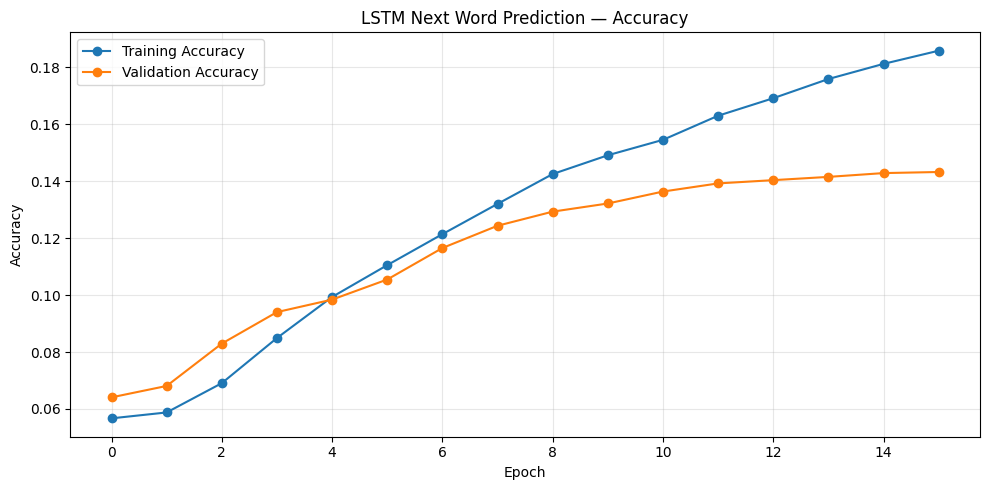

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("LSTM Next Word Prediction — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "next_word_training_accuracy.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


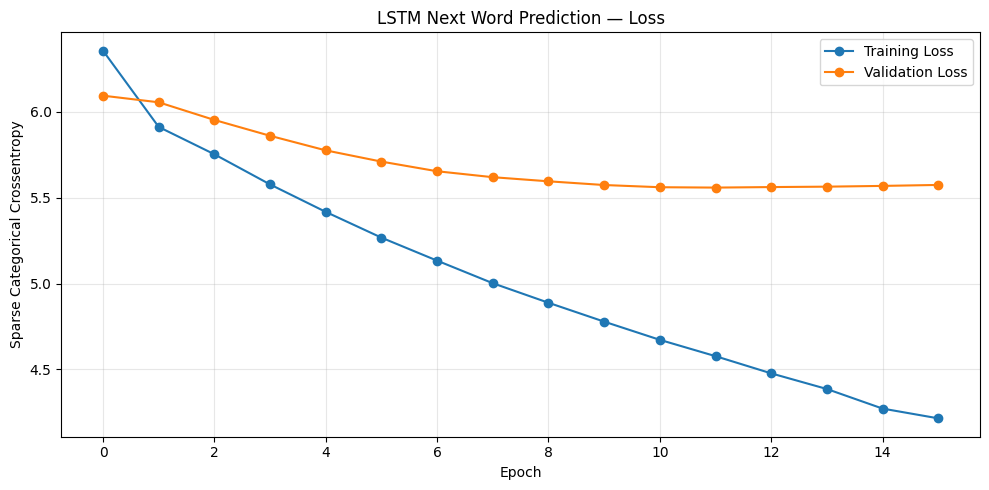

In [29]:

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("LSTM Next Word Prediction — Loss")
plt.xlabel("Epoch")
plt.ylabel("Sparse Categorical Crossentropy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "next_word_training_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [30]:

# Number of epochs completed
epochs_completed = len(history.history["loss"])

# Best epoch
best_epoch = (
    np.argmin(history.history["val_loss"]) + 1
)

# Evaluate restored model
val_loss, val_accuracy = next_word_model.evaluate(
    X_val_pad,
    y_val_next,
    verbose=0
)

print("Epochs Completed:", epochs_completed)
print("Best Epoch:", best_epoch)

print("Final Training Accuracy:",
      round(history.history["accuracy"][-1], 4))

print("Final Validation Accuracy:",
      round(history.history["val_accuracy"][-1], 4))

print("Best Validation Loss:",
      round(min(history.history["val_loss"]), 4))

print("\nRestored Model Validation Accuracy:",
      round(val_accuracy, 4))

print("Restored Model Validation Loss:",
      round(val_loss, 4))


Epochs Completed: 16
Best Epoch: 12
Final Training Accuracy: 0.1858
Final Validation Accuracy: 0.1432
Best Validation Loss: 5.5591

Restored Model Validation Accuracy: 0.1392
Restored Model Validation Loss: 5.5591



### Step 7 — LSTM Training Findings

The LSTM next-word prediction model was trained
using 20,313 training examples and 5,243
validation examples.

**Model Configuration:**
- Vocabulary size: 2,299
- Embedding dimension: 64
- LSTM units: 128
- Dropout rate: 0.30
- Total parameters: 542,523

**Training Results:**
- Epochs completed: 16
- Best epoch: 12
- Final training accuracy: 18.58%
- Final validation accuracy: 14.32%
- Best validation loss: 5.5591
- Restored validation accuracy: 13.92%

**Observations:**

Training accuracy increased steadily, indicating
that the model learned patterns from the corpus.

Validation accuracy also improved but began to
plateau during later epochs.

Validation loss reached its minimum at epoch 12
and subsequently increased slightly, suggesting
the onset of overfitting.

EarlyStopping restored the best-performing weights
from epoch 12.

**Conclusion:**

The LSTM model learned sequential word patterns
from the training corpus.

Further evaluation using Top-1 accuracy, Top-5
accuracy, and actual text predictions is required
to assess its practical performance.



## Step 8 — Model Evaluation

### Objective

Evaluate the trained LSTM model using Top-1 accuracy,
Top-5 accuracy, and qualitative next-word predictions.

### Evaluation Strategy

1. Calculate Top-1 next-word accuracy.
2. Calculate Top-5 next-word accuracy.
3. Examine sample predictions.
4. Compare predicted and actual next words.
5. Assess whether the generated suggestions are
   contextually appropriate.

### Reason

Next-word prediction is a multiclass NLP problem.
A model may generate a reasonable alternative word
even when its Top-1 prediction does not exactly
match the target word.

Therefore, Top-5 accuracy and human evaluation
provide additional information beyond Top-1 accuracy.


In [31]:

import numpy as np

# Predict next-word probabilities
val_probabilities = next_word_model.predict(
    X_val_pad,
    batch_size=64,
    verbose=1
)

print("Prediction Matrix Shape:", val_probabilities.shape)

# Most probable word ID
val_predicted_ids = np.argmax(
    val_probabilities,
    axis=1
)

print("Total Predicted Words:", len(val_predicted_ids))


82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step
Prediction Matrix Shape: (5243, 2299)
Total Predicted Words: 5243


In [32]:

# Top-1 accuracy
top1_accuracy = np.mean(
    val_predicted_ids == y_val_next
)

# Get five highest-probability word IDs
top5_indices = np.argsort(
    val_probabilities,
    axis=1
)[:, -5:]

# Check whether actual next word is in Top 5
top5_accuracy = np.mean(
    np.any(
        top5_indices == y_val_next[:, None],
        axis=1
    )
)

print("Model Evaluation Results")
print("-" * 40)

print(f"Top-1 Accuracy: {top1_accuracy * 100:.2f}%")
print(f"Top-5 Accuracy: {top5_accuracy * 100:.2f}%")


Model Evaluation Results
----------------------------------------
Top-1 Accuracy: 13.92%
Top-5 Accuracy: 29.87%


In [33]:

# Reverse vocabulary lookup
index_to_word = {
    index: word
    for word, index in tokenizer.word_index.items()
    if index < vocab_size
}

def decode_sequence(sequence):
    words = [
        index_to_word.get(int(token), "<OOV>")
        for token in sequence
        if token != 0
    ]
    return " ".join(words)


# Display sample predictions
results = []

for i in range(10):
    input_text = decode_sequence(X_val_pad[i])

    actual_word = index_to_word.get(
        int(y_val_next[i]),
        "<OOV>"
    )

    predicted_word = index_to_word.get(
        int(val_predicted_ids[i]),
        "<OOV>"
    )

    results.append({
        "Input Text": input_text,
        "Actual Next Word": actual_word,
        "Predicted Next Word": predicted_word,
        "Correct": actual_word == predicted_word
    })

results_df = pd.DataFrame(results)

display(results_df)


,Input Text,Actual Next Word,Predicted Next Word,Correct
0,said,the,the,True
1,said the,rabbit,queen,False
2,said the rabbit,in,was,False
3,said the rabbit in,a,a,True
4,said the rabbit in a,low,little,False
5,said the rabbit in a low,hurried,voice,False
6,said the rabbit in a low hurried,tone,voice,False
7,you,must,can,False
8,you must,remember,be,False
9,you must remember,remarked,a,False


In [34]:

def get_top_predictions(
    input_sequence,
    probabilities,
    top_n=5
):
    top_indices = np.argsort(
        probabilities
    )[-top_n:][::-1]

    predictions = []

    for index in top_indices:
        word = index_to_word.get(
            int(index),
            "<OOV>"
        )

        probability = float(probabilities[index])

        predictions.append({
            "Word": word,
            "Probability": round(
                probability * 100, 2
            )
        })

    return pd.DataFrame(predictions)


# Example validation input
sample_index = 10

print("Input Text:")
print(decode_sequence(X_val_pad[sample_index]))

print("\nActual Next Word:")
print(
    index_to_word.get(
        int(y_val_next[sample_index]),
        "<OOV>"
    )
)

print("\nTop 5 Predicted Words:")
display(
    get_top_predictions(
        X_val_pad[sample_index],
        val_probabilities[sample_index],
        top_n=5
    )
)


Input Text:
you must remember remarked

Actual Next Word:
the

Top 5 Predicted Words:


,Word,Probability
0,to,3.00
1,said,2.64
2,it,2.29
3,i,2.20
4,she,1.88



### Step 8 — Model Evaluation Findings

The LSTM model was evaluated on 5,243 validation
next-word prediction examples.

**Results:**
- Top-1 Accuracy: 13.92%
- Top-5 Accuracy: 29.87%
- Best Validation Loss: 5.5591

**Observations:**

1. The model correctly predicted the exact next word
   in 13.92% of validation examples.

2. The correct next word appeared among the top five
   predictions in 29.87% of examples.

3. Some predicted words were grammatically plausible
   but differed from the actual next word.

4. For the input "you must remember remarked",
   the correct word "the" was not among the top five.

5. The model's performance is limited by its
   relatively small, single-book training corpus.

**Conclusion:**

The model has learned basic statistical and sequential
patterns in English text but does not reliably predict
the correct next word.

Larger and more diverse datasets, improved tokenization,
and advanced language models could improve performance.



## Step 9 — Interactive Next Word Prediction

### Objective

Develop a function that accepts user-provided text
and predicts the most probable next words using
the trained LSTM model.

### Functionality

1. Accept user input text.
2. Apply the same preprocessing used during training.
3. Convert text into token IDs.
4. Pad the sequence to 20 tokens.
5. Generate next-word probabilities using LSTM.
6. Display the Top-5 candidate words and probabilities.

### Expected Outcome

A reusable next-word prediction function suitable
for testing and live demonstration.


In [36]:

import numpy as np
import pandas as pd
import re

from tensorflow.keras.preprocessing.sequence import pad_sequences

def predict_next_words(text, top_n=5):

    # Clean input using the same rules as training
    cleaned_text = clean_sentence(text)

    if not cleaned_text:
        return pd.DataFrame(
            columns=["Predicted Word", "Probability (%)"]
        )

    # Convert to token IDs
    token_sequence = tokenizer.texts_to_sequences(
        [cleaned_text]
    )[0]

    if not token_sequence:
        return pd.DataFrame(
            columns=["Predicted Word", "Probability (%)"]
        )

    # Pad sequence to fixed context length
    padded_sequence = pad_sequences(
        [token_sequence],
        maxlen=CONTEXT_LENGTH,
        padding="pre",
        truncating="pre"
    )

    # Predict next-word probabilities
    probabilities = next_word_model.predict(
        padded_sequence,
        verbose=0
    )[0]

    # Exclude padding and OOV token from suggestions
    probabilities = probabilities.copy()
    probabilities[0] = 0

    if len(probabilities) > 1:
        probabilities[1] = 0

    # Retrieve highest-probability words
    top_indices = np.argsort(
        probabilities
    )[-top_n:][::-1]

    predictions = []

    for index in top_indices:
        word = index_to_word.get(int(index), "<OOV>")

        predictions.append({
            "Predicted Word": word,
            "Probability (%)": round(
                float(probabilities[index]) * 100,
                2
            )
        })

    return pd.DataFrame(predictions)


print("Next-word prediction function created!")


Next-word prediction function created!


In [37]:

test_phrases = [
    "alice was beginning to",
    "the white rabbit",
    "said the queen",
    "she was very",
    "i don't know"
]

for phrase in test_phrases:
    print("\nInput:", phrase)
    display(predict_next_words(phrase, top_n=5))
    print("-" * 50)



Input: alice was beginning to


,Predicted Word,Probability (%)
0,the,8.92
1,be,5.67
2,a,4.04
3,see,3.37
4,herself,3.20


--------------------------------------------------

Input: the white rabbit


,Predicted Word,Probability (%)
0,was,4.84
1,said,3.20
2,who,2.99
3,had,2.74
4,in,2.07


--------------------------------------------------

Input: said the queen


,Predicted Word,Probability (%)
0,was,8.22
1,and,5.41
2,said,4.79
3,had,4.18
4,s,4.04


--------------------------------------------------

Input: she was very


,Predicted Word,Probability (%)
0,little,2.09
1,good,1.06
2,curious,1.00
3,glad,0.93
4,head,0.82


--------------------------------------------------

Input: i don't know


,Predicted Word,Probability (%)
0,it,13.27
1,you,8.45
2,what,4.16
3,the,3.91
4,to,3.86


--------------------------------------------------


In [38]:

user_text = input("Enter a sentence: ")

print("\nInput:", user_text)
print("\nTop 5 Next-Word Predictions:")

display(predict_next_words(user_text, top_n=5))


Enter a sentence: alice was beginning to

Input: alice was beginning to

Top 5 Next-Word Predictions:


,Predicted Word,Probability (%)
0,the,8.92
1,be,5.67
2,a,4.04
3,see,3.37
4,herself,3.20


In [39]:

def generate_text(seed_text, num_words=5):

    generated_text = seed_text.strip()

    for _ in range(num_words):

        predictions = predict_next_words(
            generated_text,
            top_n=1
        )

        if predictions.empty:
            break

        next_word = predictions.iloc[0]["Predicted Word"]

        generated_text += " " + next_word

    return generated_text


# Test text generation
print(generate_text(
    "alice was beginning to",
    num_words=5
))


alice was beginning to the other thing and the



### Step 9 — Interactive Prediction Findings

An interactive next-word prediction function was
implemented using the trained LSTM model.

The function accepts text input and returns the
five highest-probability next-word suggestions.

**Sample Predictions:**

1. "alice was beginning to" → the (8.92%)
2. "the white rabbit" → was (4.84%)
3. "said the queen" → was (8.22%)
4. "she was very" → little (2.09%)
5. "i don't know" → it (13.27%)

**Text Generation Result:**

Input: alice was beginning to

Generated:
alice was beginning to the other thing and the

**Observations:**

The model has learned common sequential word patterns.

Some predictions are grammatically plausible, while
others are inaccurate or lack contextual coherence.

The model is limited by its relatively small
single-book training corpus.

**Conclusion:**

The interactive prediction function demonstrates
the LSTM's ability to generate next-word suggestions,
although prediction quality requires improvement
for practical text-generation applications.



## Step 10 — Save Model and Tokenizer

### Objective

Save the trained LSTM model and tokenizer for
reuse in an interactive prediction application.

### Approach

1. Save the best LSTM model in Keras format.
2. Export the trained tokenizer as JSON.
3. Save the model configuration.
4. Reload the saved artifacts.
5. Verify that predictions remain consistent.

### Expected Outcome

Reusable model artifacts that allow next-word
prediction without retraining.


In [40]:

import json
import os

# Save restored best model
next_word_model.save("next_word_lstm.keras")

# Save tokenizer
tokenizer_json = tokenizer.to_json()

with open("tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer_json)

# Save configuration
model_config = {
    "vocab_size": vocab_size,
    "context_length": CONTEXT_LENGTH,
    "embedding_dim": EMBEDDING_DIM,
    "lstm_units": LSTM_UNITS,
    "dropout_rate": DROPOUT_RATE
}

with open("model_config.json", "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=2)

print("Model artifacts saved successfully!")

for filename in [
    "next_word_lstm.keras",
    "tokenizer.json",
    "model_config.json"
]:
    print(filename, os.path.getsize(filename), "bytes")


Model artifacts saved successfully!
next_word_lstm.keras 6540328 bytes
tokenizer.json 189646 bytes
model_config.json 115 bytes


In [41]:

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.text import (
    tokenizer_from_json
)

# Reload model
loaded_model = load_model(
    "next_word_lstm.keras",
    compile=False
)

# Reload tokenizer
with open("tokenizer.json", "r", encoding="utf-8") as f:
    loaded_tokenizer = tokenizer_from_json(f.read())

# Reload configuration
with open("model_config.json", "r", encoding="utf-8") as f:
    loaded_config = json.load(f)

# Test identical text
sample_text = "the white rabbit"

cleaned_text = clean_sentence(sample_text)

# Tokenize using original and loaded tokenizer
original_tokens = tokenizer.texts_to_sequences(
    [cleaned_text]
)

loaded_tokens = loaded_tokenizer.texts_to_sequences(
    [cleaned_text]
)

assert original_tokens == loaded_tokens

# Pad input
sample_padded = pad_sequences(
    original_tokens,
    maxlen=CONTEXT_LENGTH,
    padding="pre",
    truncating="pre"
)

# Compare predictions
original_prob = next_word_model.predict(
    sample_padded,
    verbose=0
)

loaded_prob = loaded_model.predict(
    sample_padded,
    verbose=0
)

assert np.allclose(
    original_prob,
    loaded_prob,
    atol=1e-5
)

print("Original Top Word ID:", np.argmax(original_prob))
print("Loaded Top Word ID:", np.argmax(loaded_prob))

print("\nModel reload validation successful!")


Original Top Word ID: 12
Loaded Top Word ID: 12

Model reload validation successful!


In [42]:

from google.colab import files

files.download("next_word_lstm.keras")
files.download("tokenizer.json")
files.download("model_config.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### Step 10 — Model Serialization Findings

The trained LSTM model was saved successfully
in Keras format.

The tokenizer vocabulary and model settings
were exported as JSON files.

Saved artifacts:
- next_word_lstm.keras
- tokenizer.json
- model_config.json

The saved model and tokenizer were reloaded
and tested for prediction consistency.

**Conclusion:**

The model artifacts are ready for integration
into a Next Word Prediction demonstration app.
